# 04 · Chapter 2: a blood test
Tumor-educated platelet RNA (Best et al. 2015, 2017). Here the signal is weaker than in tissue, and confounding by hospital, age and batch has to be ruled out.

In [1]:
import os, glob
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.precision', 3); pd.set_option('display.max_rows', 80)
R = 'results/blood'
TAB, FIG = f'{R}/tables', f'{R}/figures'
summary = pd.read_csv(f'{TAB}/summary.csv')
best = lambda k: (summary[(summary.model == 'logreg') & (summary.k == k) & ~summary.selector.isin(['random', 'variance', 'all_genes'])]
                  .groupby(['cancer', 'task']).auc_mean.max().rename(f'best_{k}'))

## Minimal panel per task
Smallest panel that is non-inferior to all genes (corrected repeated-CV test), and the smallest reaching 90% sensitivity at 95% specificity.

In [2]:
pd.read_csv(f'{TAB}/minimal_panel.csv')

,cancer,task,model,n_genes_all,auc_all_genes,auc_best_1,auc_best_10,smallest_retained_k,auc_random_10,smallest_k_sens90,sens_all_genes
0,GSE68086,cancer_type,logreg,6640,0.873,0.674,0.790,NaN,0.656,NaN,NaN
1,GSE68086,pancancer_vs_healthy,logreg,6950,0.986,0.898,0.951,NaN,0.854,100.0,0.949
2,GSE68086_batch234,pancancer_vs_healthy,logreg,6938,0.983,0.933,0.953,NaN,0.851,50.0,0.939
3,GSE89843,nonmetastatic_vs_noncancer,logreg,4694,0.971,0.858,0.903,NaN,0.758,NaN,0.819
4,GSE89843,nsclc_vs_healthy,logreg,4694,0.984,0.840,0.938,NaN,0.745,500.0,0.933
5,GSE89843,nsclc_vs_noncancer,logreg,4694,0.962,0.838,0.904,NaN,0.735,NaN,0.809
6,GSE89843_VUMC,nsclc_vs_noncancer,logreg,4694,0.971,0.872,0.938,NaN,0.778,NaN,0.857
7,GSE89843_matched,nsclc_vs_noncancer,logreg,4694,0.950,0.830,0.914,NaN,0.742,NaN,0.793


## AUC as the panel shrinks (logistic regression)

In [3]:
allg = summary[(summary.model == 'logreg') & (summary.selector == 'all_genes')].set_index(['cancer', 'task']).auc_mean.rename('all_genes')
rnd = summary[(summary.model == 'logreg') & (summary.selector == 'random') & (summary.k == 10)].set_index(['cancer', 'task']).auc_mean.rename('random_10')
pd.concat([allg, best(500), best(50), best(10), best(5), best(1), rnd], axis=1)

all_genes  best_500  best_50  \
cancer            task                                                       
GSE68086          cancer_type                     0.873     0.868    0.841   
                  pancancer_vs_healthy            0.986     0.978    0.971   
GSE68086_batch234 pancancer_vs_healthy            0.983     0.977    0.971   
GSE89843          nonmetastatic_vs_noncancer      0.971     0.963    0.929   
                  nsclc_vs_healthy                0.984     0.979    0.963   
                  nsclc_vs_noncancer              0.962     0.956    0.936   
GSE89843_VUMC     nsclc_vs_noncancer              0.971     0.961    0.952   
GSE89843_matched  nsclc_vs_noncancer              0.950     0.948    0.937   

                                              best_10  best_5  best_1  \
cancer            task                                                  
GSE68086          cancer_type                   0.790   0.767   0.674   
                  pancancer_vs_healthy          0.951   0.930   0.898   
GSE68086_batch234 pancancer_vs_healthy          0.953   0.947   0.933   
GSE89843          nonmetastatic_vs_noncancer    0.903   0.902   0.858   
                  nsclc_vs_healthy              0.938   0.906   0.840   
                  nsclc_vs_noncancer            0.904   0.879   0.838   
GSE89843_VUMC     nsclc_vs_noncancer            0.938   0.925   0.872   
GSE89843_matched  nsclc_vs_noncancer            0.914   0.894   0.830   

                                              random_10  
cancer            task                                   
GSE68086          cancer_type                     0.656  
                  pancancer_vs_healthy            0.854  
GSE68086_batch234 pancancer_vs_healthy            0.851  
GSE89843          nonmetastatic_vs_noncancer      0.758  
                  nsclc_vs_healthy                0.745  
                  nsclc_vs_noncancer              0.735  
GSE89843_VUMC     nsclc_vs_noncancer              0.778  
GSE89843_matched  nsclc_vs_noncancer              0.742

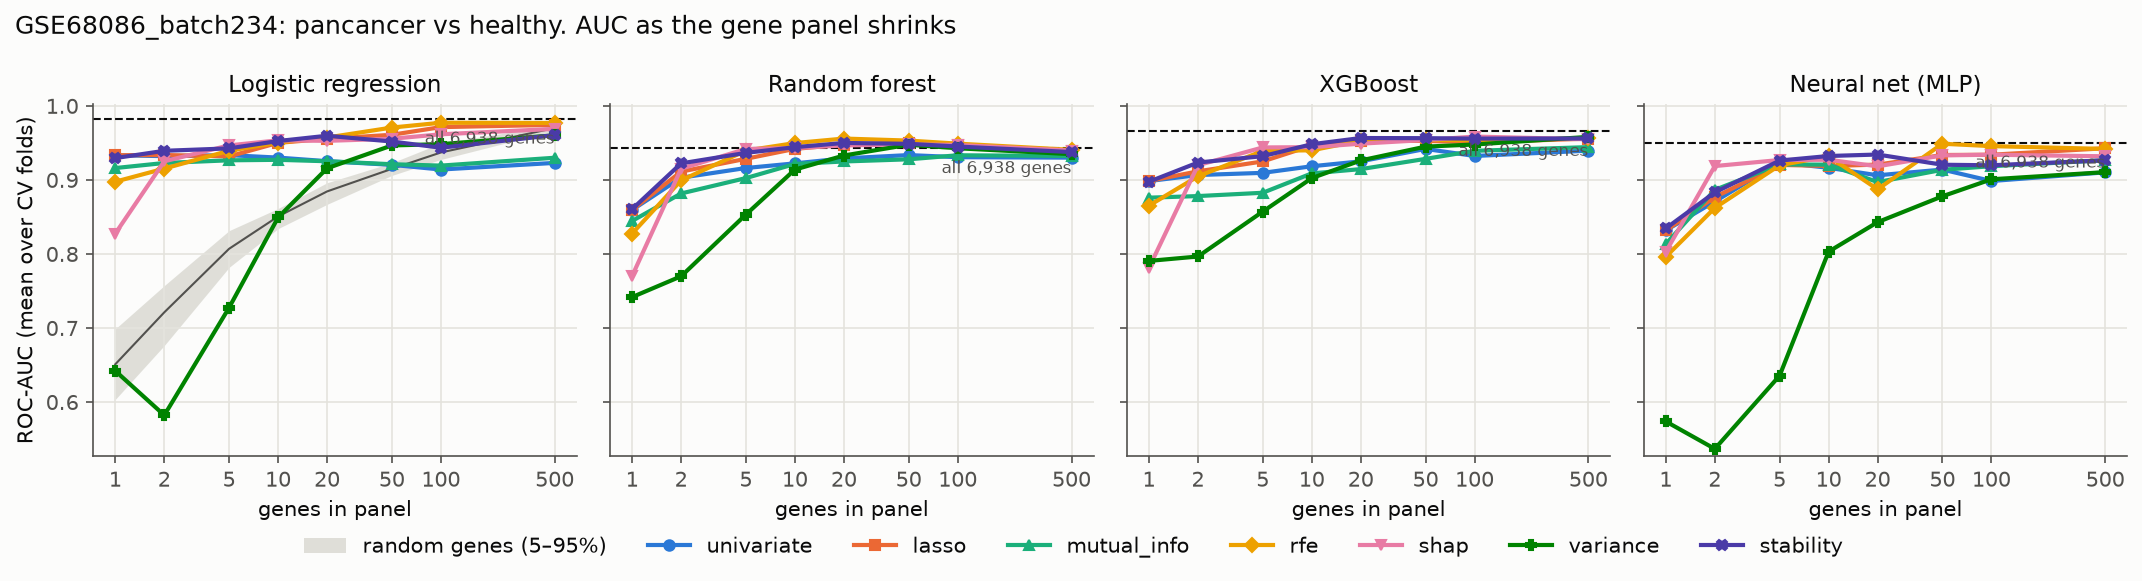

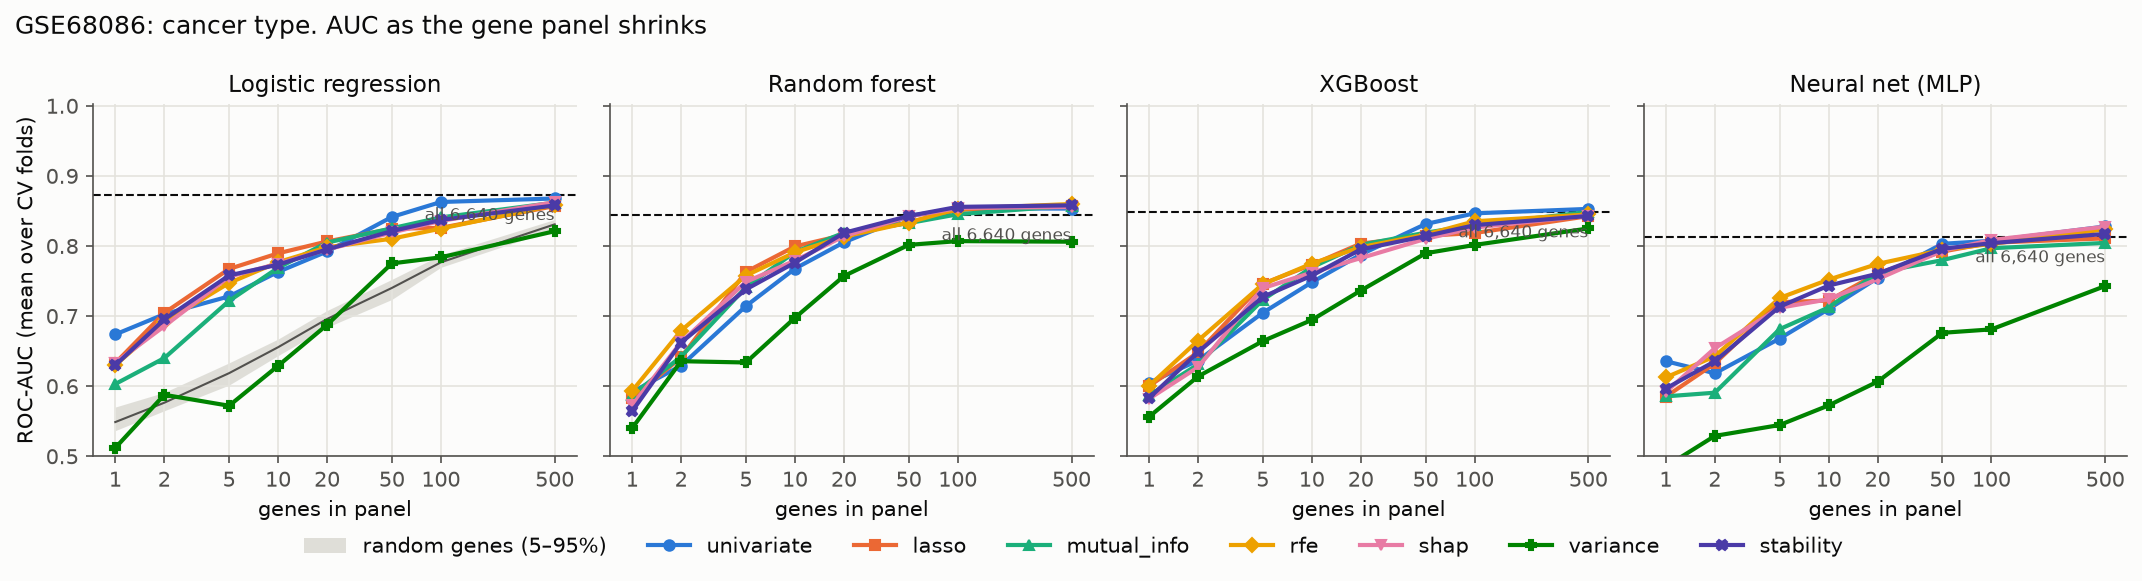

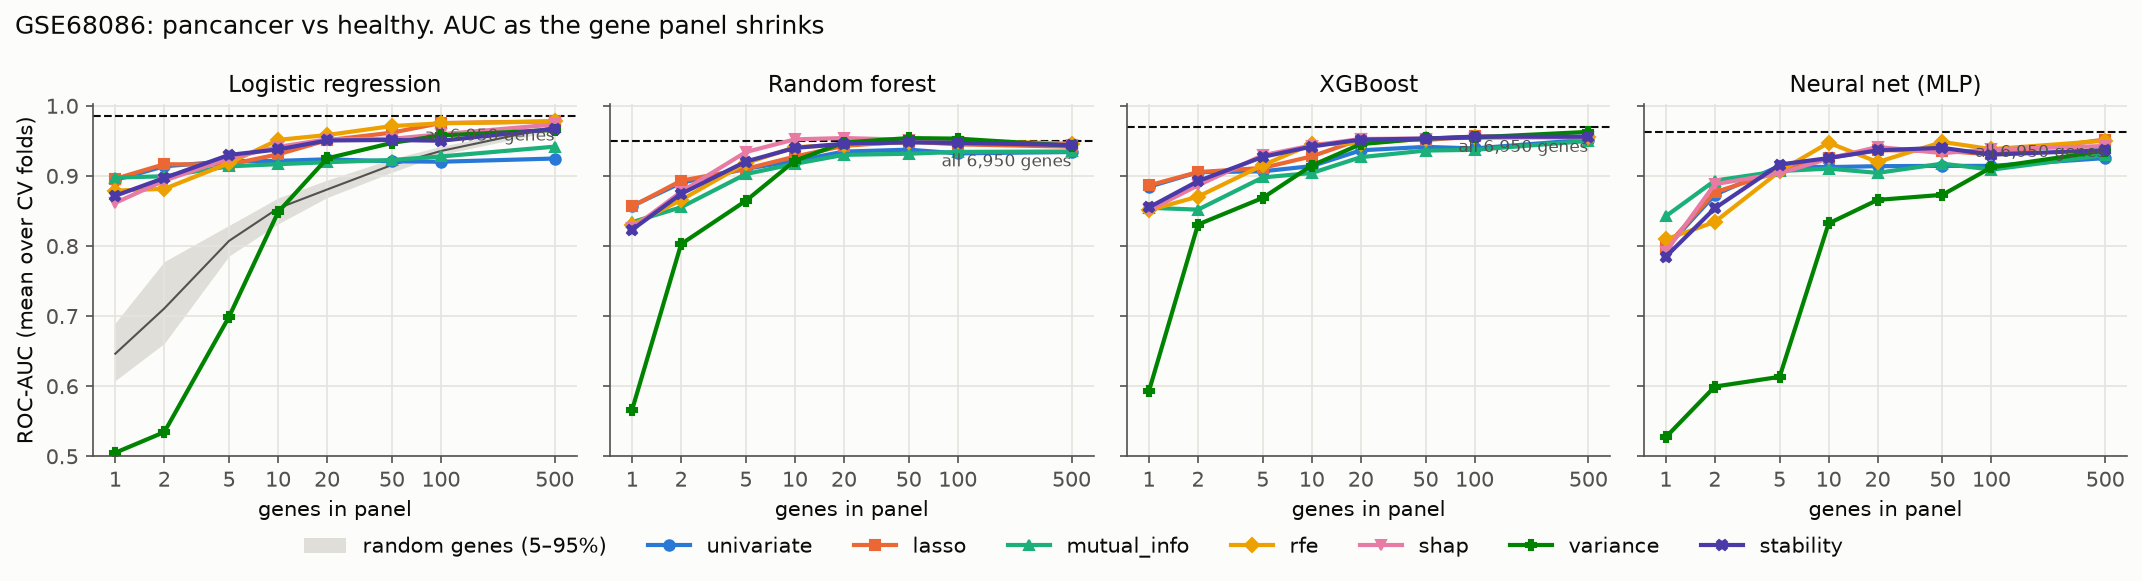

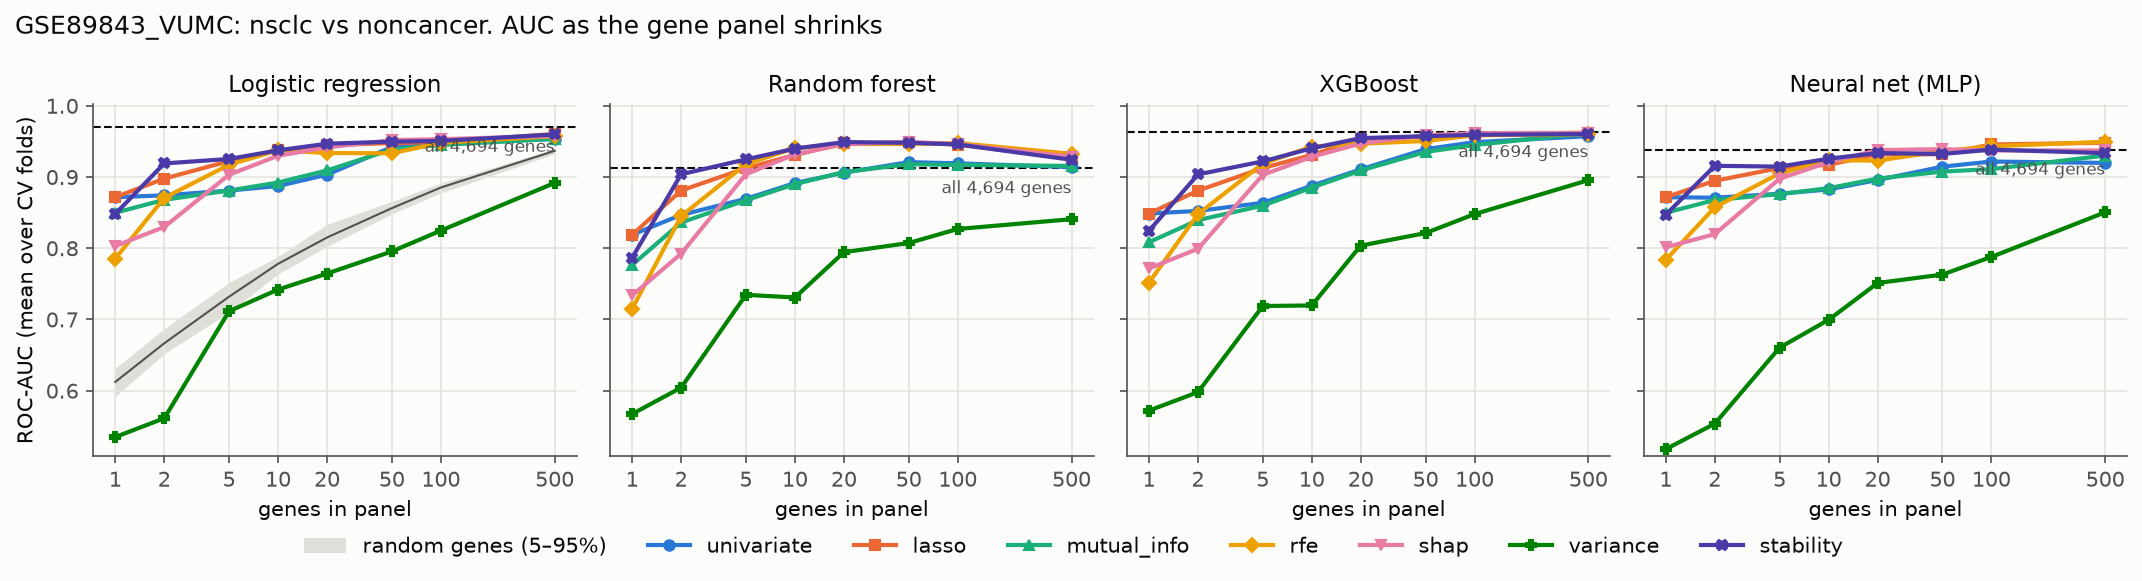

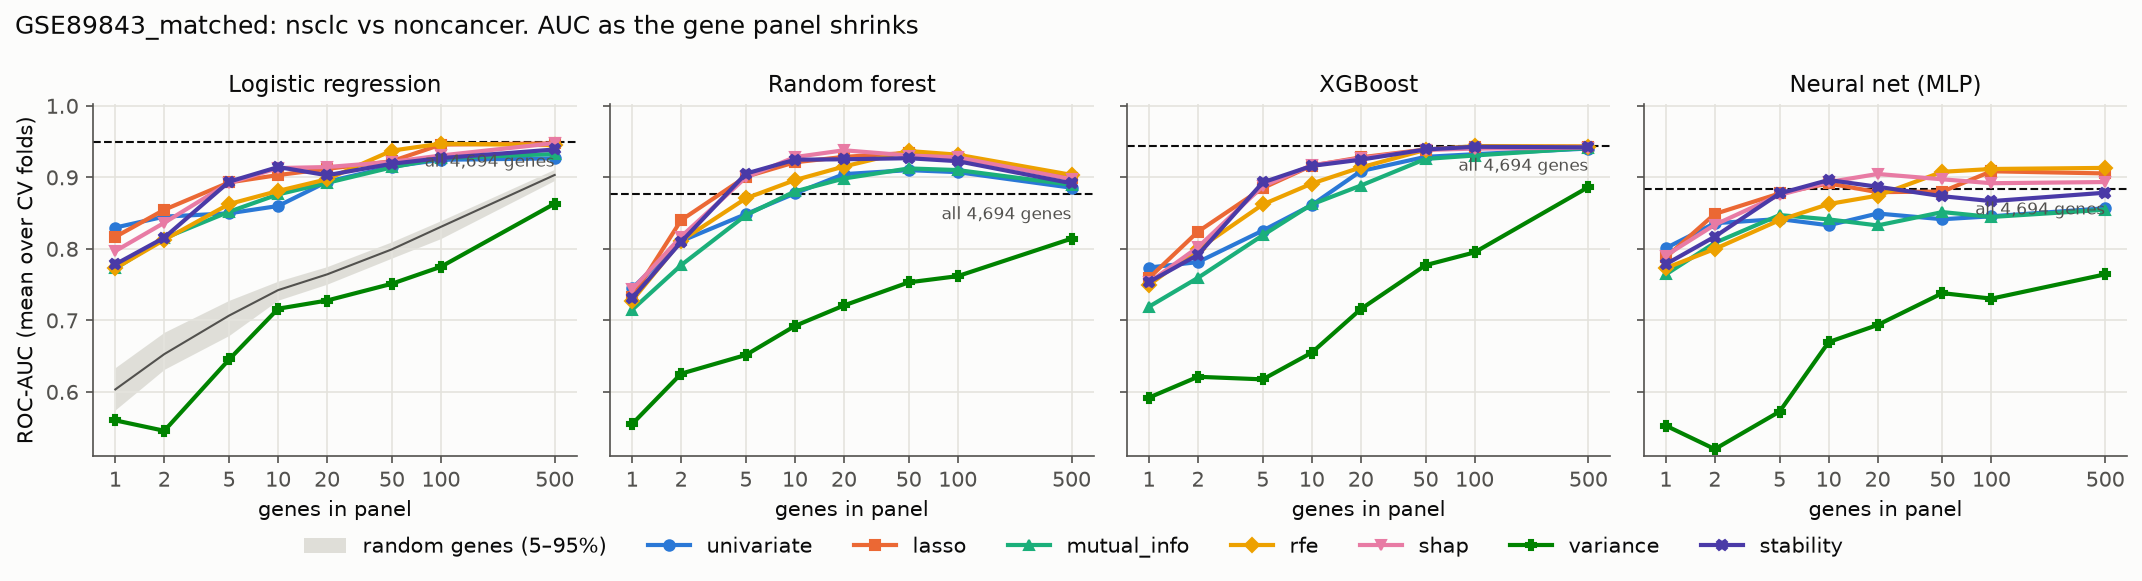

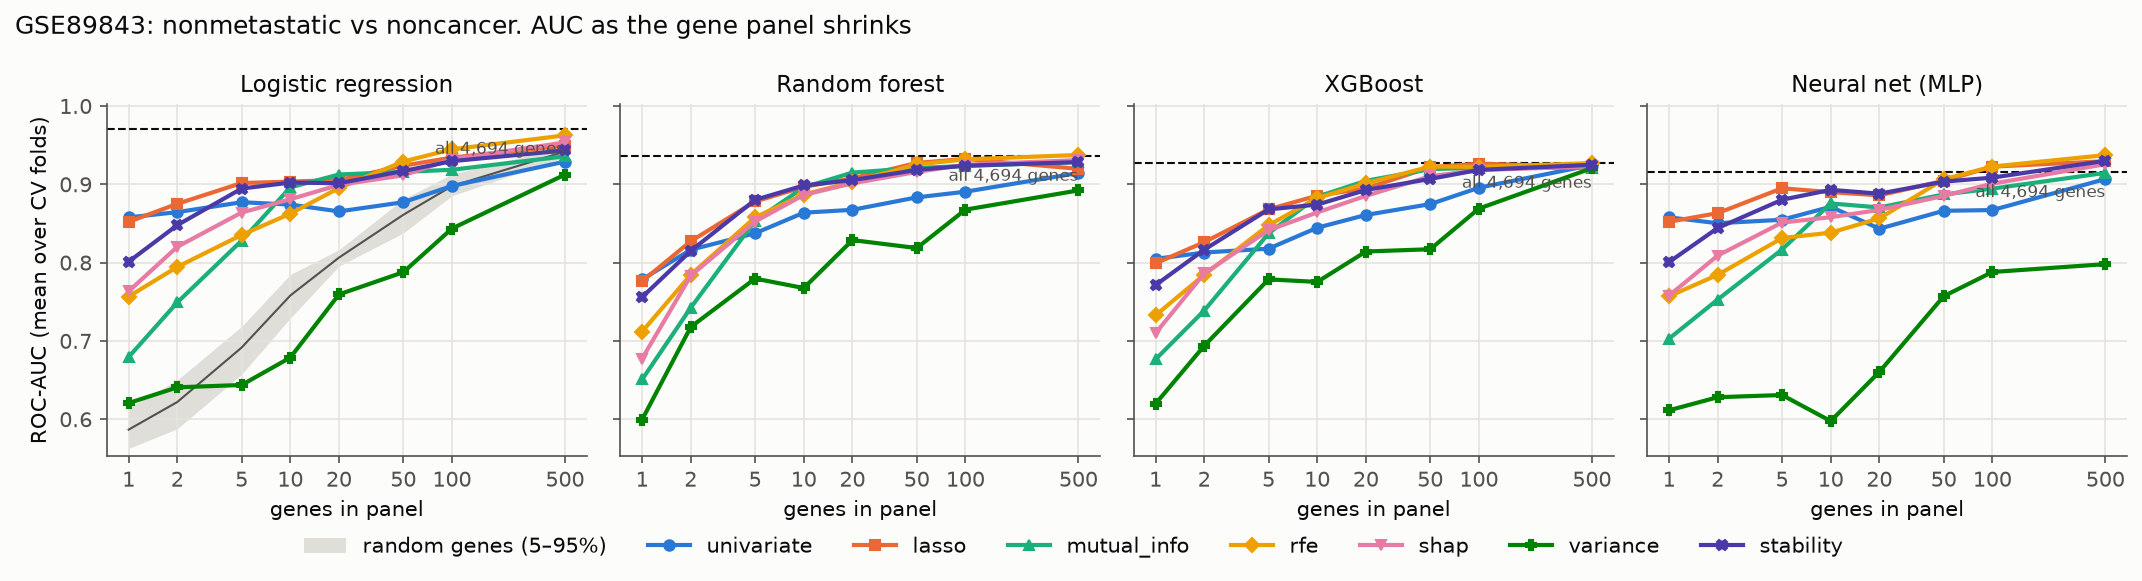

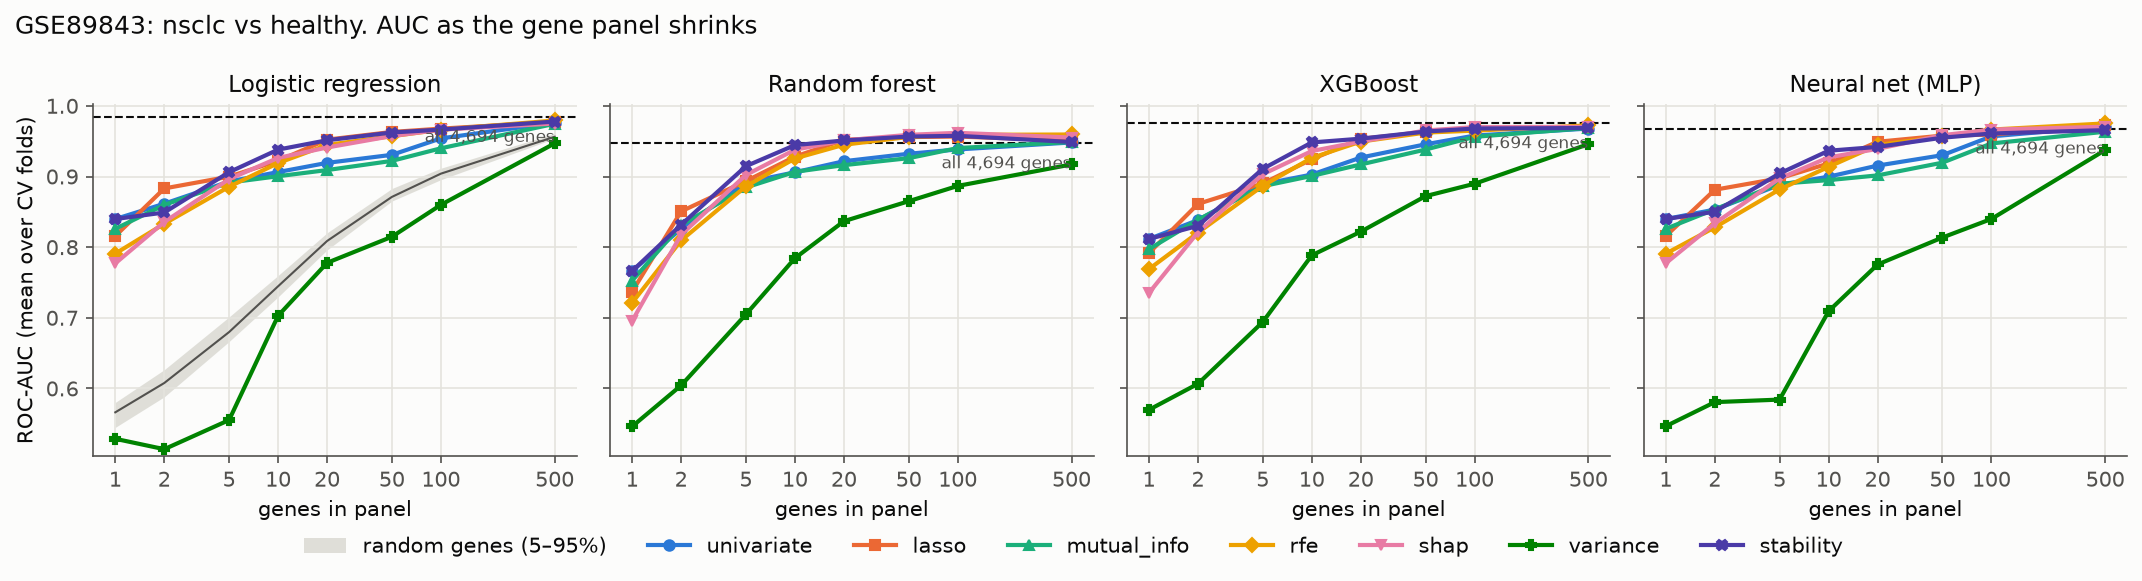

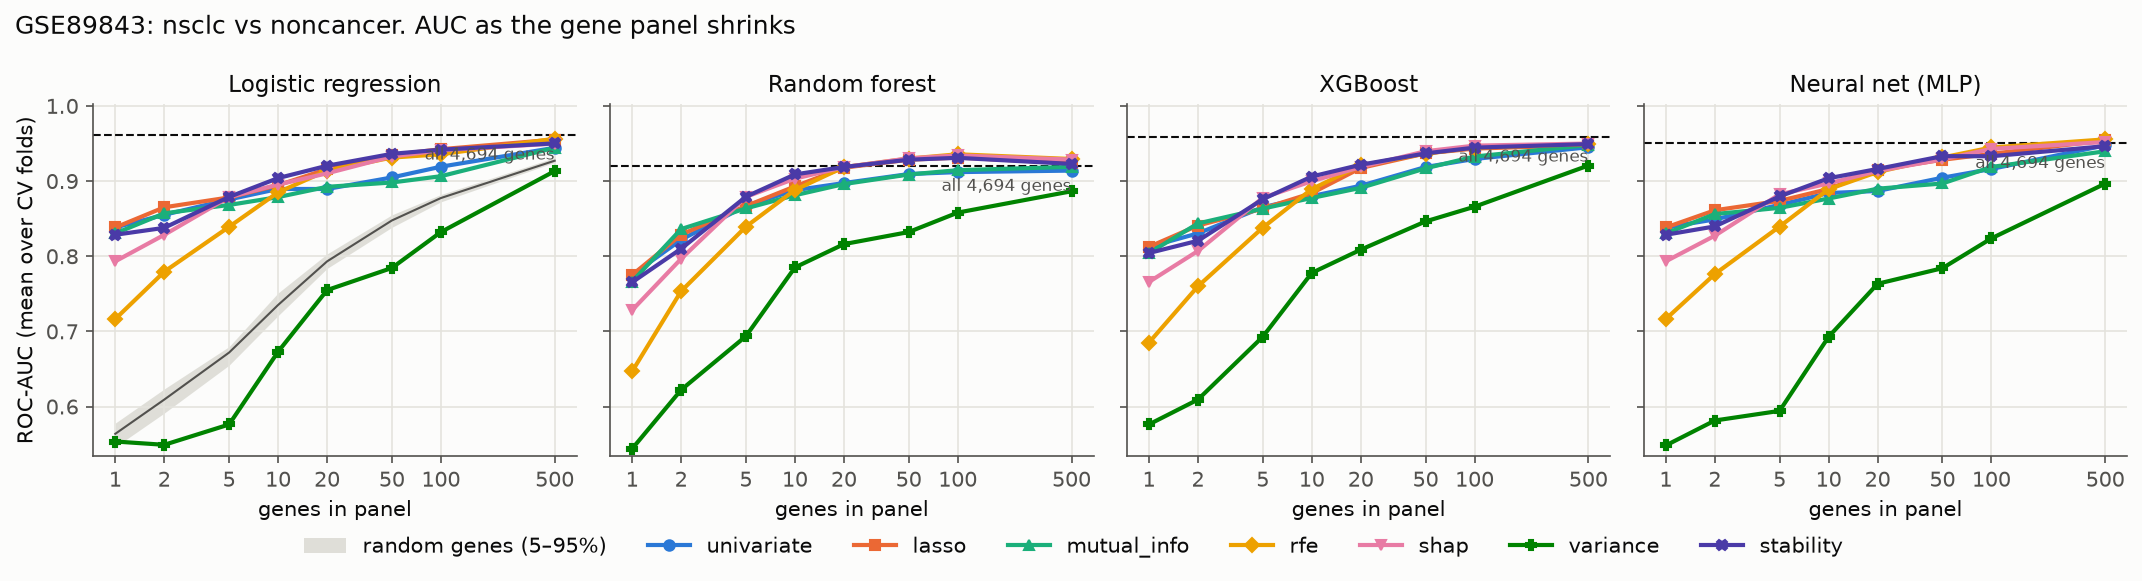

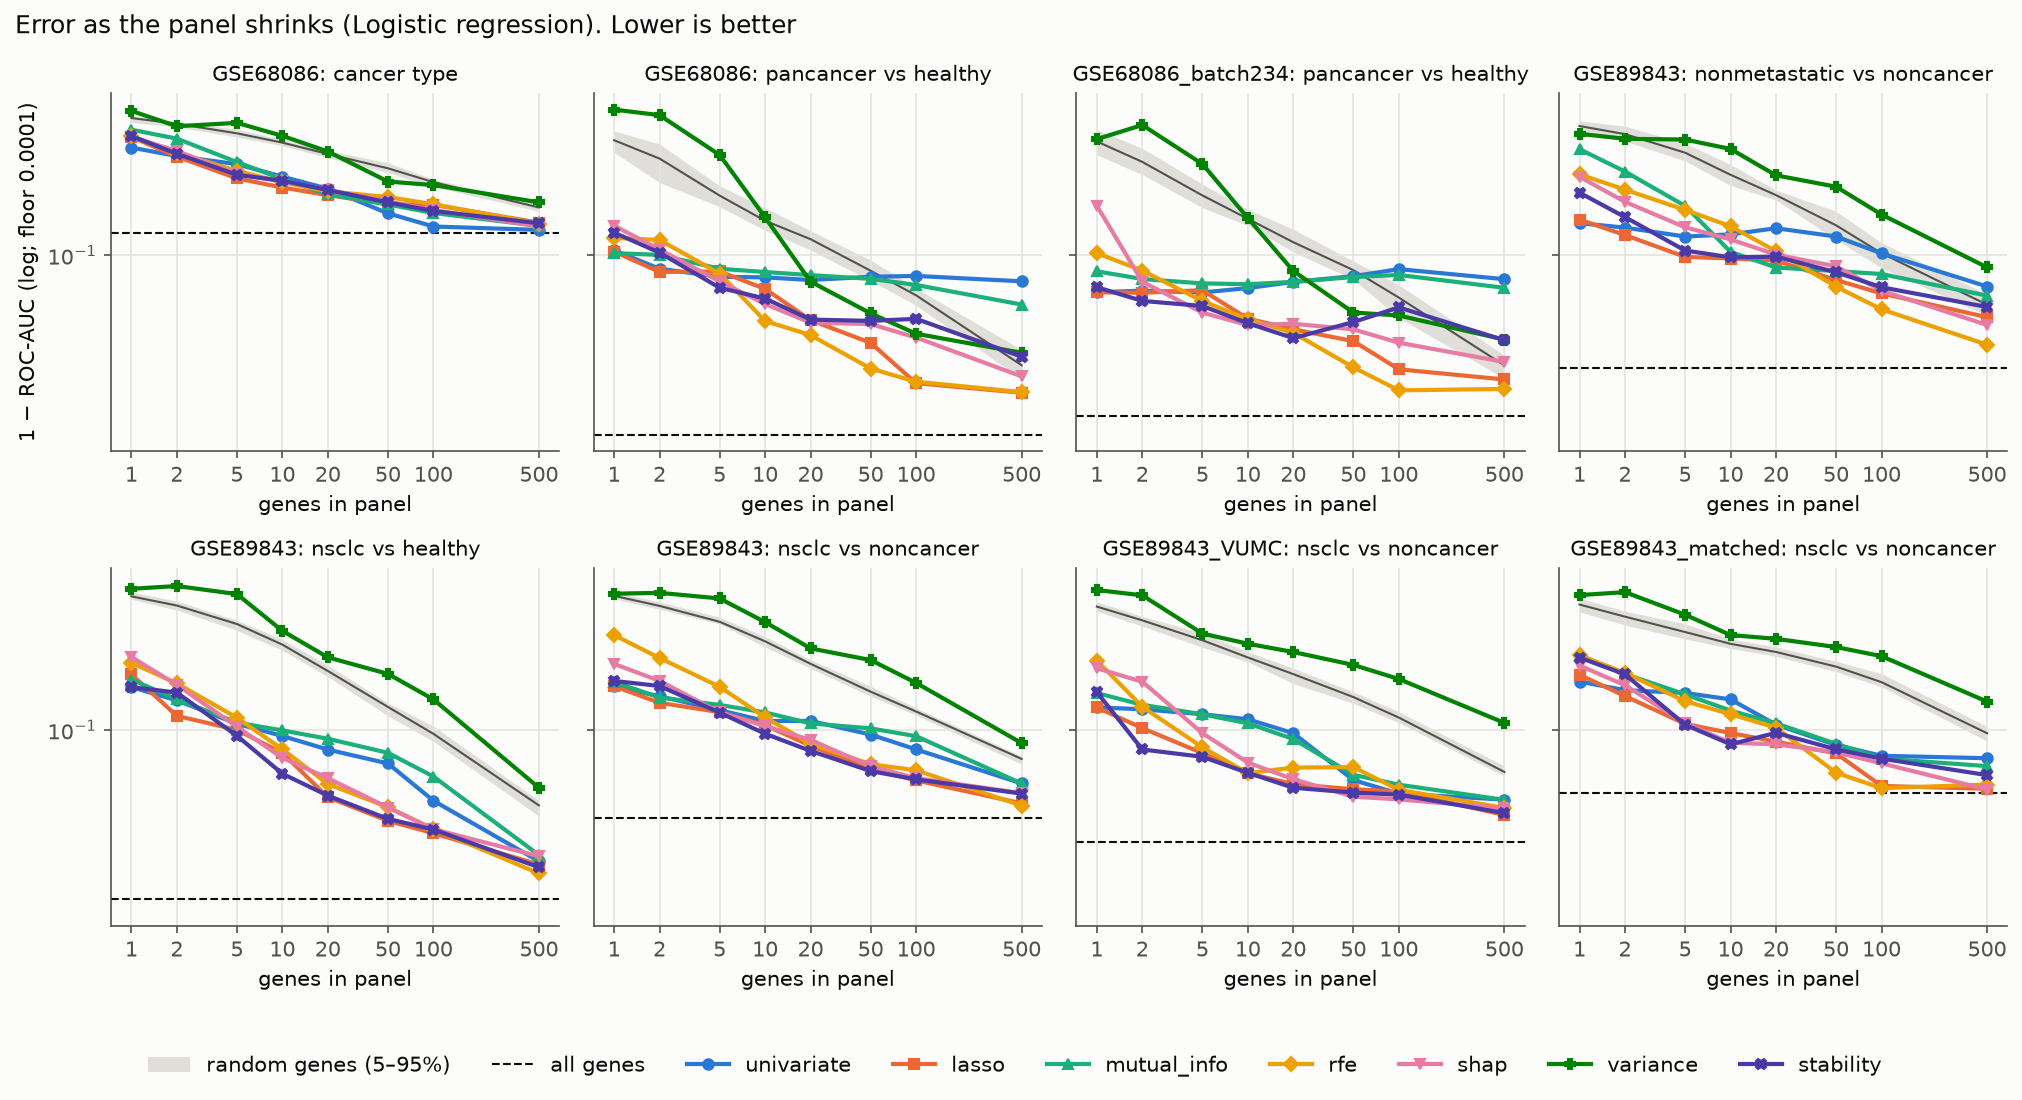

In [4]:
for f in sorted(glob.glob(f'{FIG}/auc_vs_k_*.png')) + [f'{FIG}/error_vs_k_logreg.png']:
    display(Image(f))

## Confounding: what can metadata alone predict?
If hospital or age alone separates the groups, a gene model may be learning those instead of cancer.

In [5]:
pd.read_csv(f'{TAB}/confounders.csv')

,cancer,task,features,auc_mean,auc_lo,auc_hi
0,GSE89843,nsclc_vs_healthy,hospital only,0.810,0.787,0.832
1,GSE89843,nsclc_vs_healthy,age only,0.855,0.819,0.890
2,GSE89843,nsclc_vs_healthy,age + sex + smoking,0.886,0.854,0.918
3,GSE89843,nsclc_vs_healthy,hospital + age + sex + smoking,0.945,0.922,0.969
4,GSE89843,nsclc_vs_noncancer,hospital only,0.811,0.779,0.842
5,GSE89843,nsclc_vs_noncancer,age only,0.810,0.776,0.844
6,GSE89843,nsclc_vs_noncancer,age + sex + smoking,0.843,0.820,0.866
7,GSE89843,nsclc_vs_noncancer,hospital + age + sex + smoking,0.931,0.913,0.949
8,GSE89843,nonmetastatic_vs_noncancer,hospital only,0.859,0.791,0.927
9,GSE89843,nonmetastatic_vs_noncancer,age only,0.844,0.808,0.880


### Site signature: platelet RNA of *non-cancer* people, VUMC vs other hospitals

In [6]:
pd.read_csv(f'{TAB}/site_signature.csv')

,cancer,contrast,n_vumc,n_other,genes,auc_mean,auc_min,auc_max
0,GSE89843,non-cancer: VUMC vs other hospitals,317,60,all,0.902,0.796,0.964
1,GSE89843,non-cancer: VUMC vs other hospitals,317,60,10,0.674,0.505,0.852


### Gene-model AUC inside the overlapping age range (45-75)

In [7]:
pd.read_csv(f'{TAB}/age_restricted.csv')

,cancer,task,selector,k,auc_all_ages,auc_age_45_75,n_inside,age_auc_inside
0,GSE89843,nsclc_vs_healthy,all_genes,4694,0.983,0.975,451,0.791
1,GSE89843,nsclc_vs_healthy,lasso,1,0.825,0.776,451,0.791
2,GSE89843,nsclc_vs_healthy,lasso,5,0.893,0.850,451,0.791
3,GSE89843,nsclc_vs_healthy,lasso,10,0.920,0.880,451,0.791
4,GSE89843,nsclc_vs_healthy,lasso,50,0.960,0.936,451,0.791
5,GSE89843,nsclc_vs_healthy,stability,1,0.837,0.793,451,0.791
6,GSE89843,nsclc_vs_healthy,stability,5,0.887,0.870,451,0.791
7,GSE89843,nsclc_vs_healthy,stability,10,0.924,0.904,451,0.791
8,GSE89843,nsclc_vs_healthy,stability,50,0.958,0.934,451,0.791
9,GSE89843,nsclc_vs_healthy,univariate,1,0.837,0.793,451,0.791


## The original authors' split
Genes chosen and model fit on the authors' training + evaluation samples, scored once on their validation samples.

In [8]:
pd.read_csv(f'{TAB}/benchmark.csv')

,cancer,cohort,subset,n_train,n_validation,n_cancer,selector,k,auc,auc_lo,auc_hi
0,GSE89843,full_cohort,all validation,208,571,298,all_genes,4694,0.833,0.799,0.868
1,GSE89843,full_cohort,cancers from training hospitals,208,349,76,all_genes,4694,0.949,0.925,0.973
2,GSE89843,full_cohort,cancers from unseen hospitals,208,495,222,all_genes,4694,0.793,0.752,0.833
3,GSE89843,full_cohort,all validation,208,571,298,univariate,1,0.833,0.800,0.865
4,GSE89843,full_cohort,cancers from training hospitals,208,349,76,univariate,1,0.847,0.795,0.894
...,...,...,...,...,...,...,...,...,...,...,...
120,GSE89843_matched,matched_cohort,cancers from training hospitals,133,130,90,stability,50,0.955,0.918,0.983
121,GSE89843_matched,matched_cohort,all validation,133,130,90,stability,100,0.897,0.840,0.948
122,GSE89843_matched,matched_cohort,cancers from training hospitals,133,130,90,stability,100,0.897,0.840,0.948
123,GSE89843_matched,matched_cohort,all validation,133,130,90,stability,500,0.933,0.890,0.972


## Calibration and decision curves (out-of-fold, repeat 0)

In [9]:
pd.read_csv(f'{TAB}/calibration.csv').groupby(['cancer', 'task', 'selector', 'k']).brier.first().unstack('k')

k                                                          1      5      10    \
cancer            task                       selector                           
GSE68086          pancancer_vs_healthy       all_genes      NaN    NaN    NaN   
                                             mutual_info  0.235    NaN    NaN   
                                             rfe            NaN    NaN  0.151   
                                             stability      NaN  0.173    NaN   
GSE68086_batch234 pancancer_vs_healthy       all_genes      NaN    NaN    NaN   
                                             lasso        0.234    NaN    NaN   
                                             rfe            NaN    NaN    NaN   
                                             shap           NaN  0.156  0.082   
GSE89843          nonmetastatic_vs_noncancer all_genes      NaN    NaN    NaN   
                                             lasso          NaN  0.106  0.106   
                                             rfe            NaN    NaN    NaN   
                                             univariate   0.228    NaN    NaN   
                  nsclc_vs_healthy           all_genes      NaN    NaN    NaN   
                                             lasso          NaN    NaN    NaN   
                                             stability    0.233  0.147  0.118   
                  nsclc_vs_noncancer         all_genes      NaN    NaN    NaN   
                                             lasso        0.230    NaN    NaN   
                                             stability      NaN  0.186  0.166   
GSE89843_VUMC     nsclc_vs_noncancer         all_genes      NaN    NaN    NaN   
                                             lasso        0.233    NaN  0.092   
                                             shap           NaN    NaN    NaN   
                                             stability      NaN  0.108    NaN   
GSE89843_matched  nsclc_vs_noncancer         all_genes      NaN    NaN    NaN   
                                             rfe            NaN    NaN    NaN   
                                             stability      NaN  0.212  0.176   
                                             univariate   0.243    NaN    NaN   

k                                                          50     4694   6938  \
cancer            task                       selector                           
GSE68086          pancancer_vs_healthy       all_genes      NaN    NaN    NaN   
                                             mutual_info    NaN    NaN    NaN   
                                             rfe          0.058    NaN    NaN   
                                             stability      NaN    NaN    NaN   
GSE68086_batch234 pancancer_vs_healthy       all_genes      NaN    NaN  0.046   
                                             lasso          NaN    NaN    NaN   
                                             rfe          0.074    NaN    NaN   
                                             shap           NaN    NaN    NaN   
GSE89843          nonmetastatic_vs_noncancer all_genes      NaN  0.043    NaN   
                                             lasso          NaN    NaN    NaN   
                                             rfe          0.079    NaN    NaN   
                                             univariate     NaN    NaN    NaN   
                  nsclc_vs_healthy           all_genes      NaN  0.046    NaN   
                                             lasso        0.078    NaN    NaN   
                                             stability      NaN    NaN    NaN   
                  nsclc_vs_noncancer         all_genes      NaN  0.069    NaN   
                                             lasso          NaN    NaN    NaN   
                                             stability    0.100    NaN    NaN   
GSE89843_VUMC     nsclc_vs_noncancer         all_genes      NaN  0.058    NaN   
                              